# Introduction to ODL, function spaces and functions
With this problem sheet you should familiarize yourself with ODL’s concept of spaces of discretized functions. For now, we try to deal with an extremely simple inverse problem: taking the numerical derivative of a real function.

We must first import ODL which should be available in this environment. We will use numpy as backend for ODL, but pytorch is also an option.

In [1]:
import odl
import numpy as np
import matplotlib.pyplot as plt

In the sequel, you should do the following:

1. Define a space of functions on the closed interval $[0, 1]$ with variable discretization (you should be able to choose the number of supporting points). Use the function [odl.uniform_discr](https://odl.readthedocs.io/generated/odl.uniform_discr.html).
2. Define a nice function in this space, like $f(x) = x^3/3$ or $f(x) = \cos x$. Use the [element method](https://odl.readthedocs.io/generated/odl.DiscretizedSpace.element.html) of your space on an appropriate lambda function, e.g., ``lambda x: 2*x+np.sin(x)`` or a manually defined Python function, alternatively on a predefined numpy array with the appropriate dimensions and dtype of the space. 
3. Write down the exact derivative of this function and define it as another element in the space for comparison.
4. Add some [Gaussian noise](https://odl.readthedocs.io/generated/odl.core.phantom.noise.white_noise.html) to the function.
5. Use the [show method](https://odl.readthedocs.io/generated/odl.DiscretizedSpaceElement.show.html) for all functions you defined so far to check that your definitions are correct.
6. Apply the [gradient](https://odl.readthedocs.io/generated/odl.Gradient.html) to the "corrupted" function to calculate the derivative. Hint: To construct an ODL operator, you must specify its domain space (and range space, if different). Gradient has several optional parameters, e.g., forward or backward differentiation for gradients. You can then apply the operator to an element in the domain space, e.g., ``Grad(func)``.
7. Show the derivative and compare it with the exact solution.

Test and compare your results across different discretizations and levels of noise. (You can apply ODL's array-API functions like ``odl.mean`` or ``odl.max`` to space elements in order to quantify the error.)

Hint: If you get a message from matplotlib: Use ``plt.close('all')`` to close all the open figure windows. If you don’t see a picture with the ``show`` method, use the parameter ``force_show=True``.

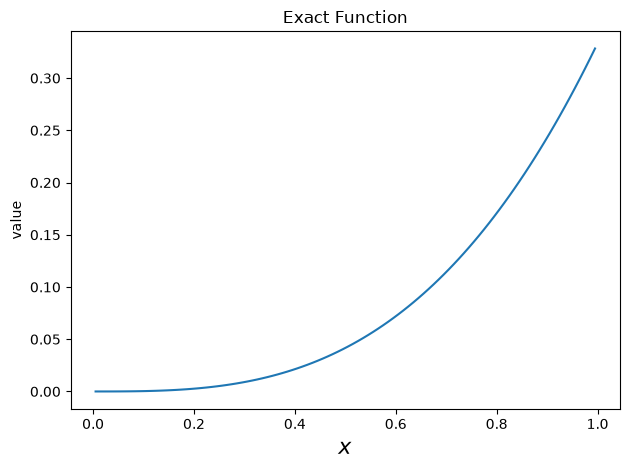

<Figure size 640x480 with 0 Axes>

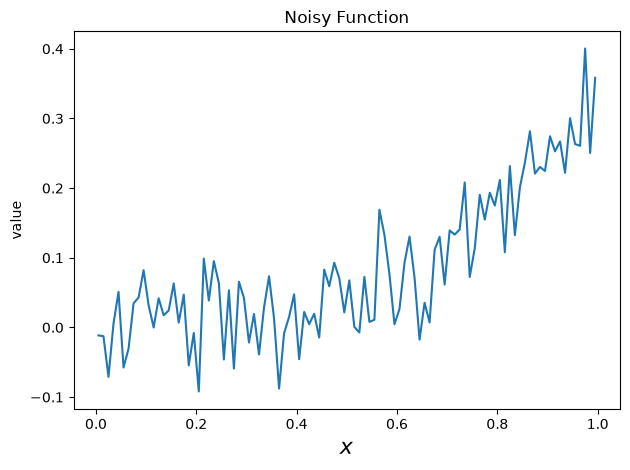

<Figure size 640x480 with 0 Axes>

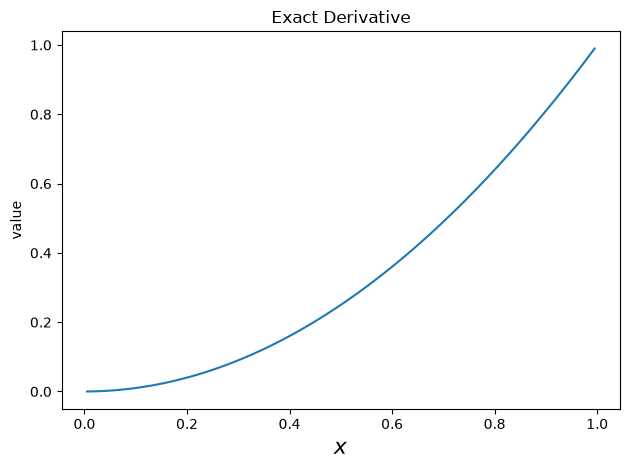

<Figure size 640x480 with 0 Axes>

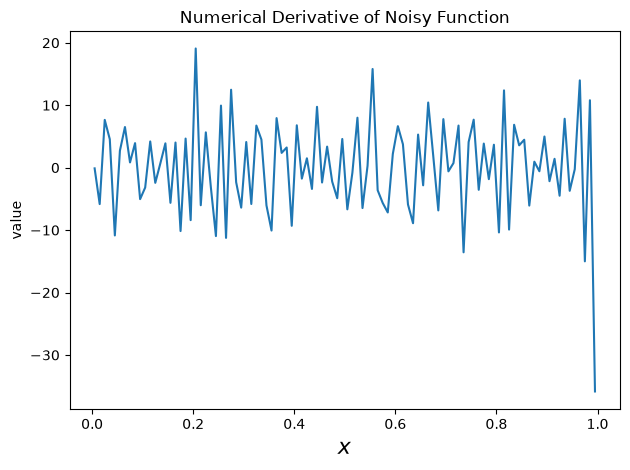

<Figure size 640x480 with 0 Axes>

Mean Absolute Error: 6.0100
Max Error: 36.8289


In [2]:
# 1. Define the space on [0, 1] with a variable number of points
n_points = 100
space = odl.uniform_discr(min_pt=0, max_pt=1, shape=n_points)

# 2. Define the function f(x) = x^3 / 3 in this space
f = space.element(lambda x: (x**3) / 3)

# 3. Define the exact derivative f'(x) = x^2 in the same space
f_deriv_exact = space.element(lambda x: x**2)

# 4. Add Gaussian white noise
# We scale the noise by a small factor to control the noise level
noise = odl.phantom.noise.white_noise(space)
noise_level = 0.05
f_noisy = f + noise_level * noise

# 5. Show the functions defined so far
f.show(title="Exact Function", force_show=True)
f_noisy.show(title="Noisy Function", force_show=True)
f_deriv_exact.show(title="Exact Derivative", force_show=True)

# 6. Apply the gradient operator to calculate the derivative
# The Gradient requires the domain space. We use 'forward' differences here.
grad_op = odl.Gradient(domain=space, method='forward')
f_deriv_num = grad_op(f_noisy)

# 7. Show the numerical derivative and compare with the exact solution
f_deriv_num.show(title="Numerical Derivative of Noisy Function", force_show=True)

# Quantify the error across the space
error = f_deriv_exact - f_deriv_num

# Use ODL's array-API functions directly
abs_error = odl.abs(error)
mean_error = odl.mean(abs_error)
max_error = odl.max(abs_error)

print(f"Mean Absolute Error: {mean_error:.4f}")
print(f"Max Error: {max_error:.4f}")

# Close plots cleanly if needed, or keep them open for viewing
# plt.close('all')